# 02b — Cost shifters and consumer demographics

**Cost shifters** (excluded from demand, used as price instruments and in the marginal-cost equation).
The Hausman fare instrument fails in this data (notebook 03), as the course notes warn when demand shocks
are common across markets. Following Berry and Haile (2014) and Armstrong (2016), we build direct cost
shifters from public cost data:

* **Fuel cost per seat**: U.S. Gulf Coast jet fuel spot price (quarter average, 2025Q2 dollars) × the
  carrier's average fuel burn per airborne hour (Form 41 P-5.2, averaged over the whole sample so that it does
  not respond to quarterly utilisation) × the itinerary's airborne hours ÷ the carrier's average seats per departure.
* **Pilot cost per seat**: the carrier's pilot and co-pilot expense per airborne hour in the quarter
  (Form 41 P-5.2, domestic operations) × itinerary airborne hours ÷ average seats. Its time variation comes
  mostly from the 2022–2024 pilot contracts (Alaska 2022, Delta, American and United 2023, Southwest 2024).

Itinerary airborne hours come from a T-100 regression of airborne minutes per departure on segment
distance, applied to the product's miles flown with one extra take-off and landing for connecting itineraries.
With route, carrier and quarter fixed effects in demand, the instruments are identified by the interaction of
common fuel-price movements and carrier-specific labour-cost changes with itinerary length.

**Demographics.** Household income distributions (ACS 2020–2024 5-year, table B19001) for each CBSA. A market's
consumers are a population-weighted mixture of its two endpoint metros. These feed the income
random-coefficient model in notebook 03b.

In [1]:
%run 00_setup.ipynb

In [2]:
import zipfile

def read_zip_csv(path):
    with zipfile.ZipFile(path) as z:
        name = max((i for i in z.infolist() if i.filename.lower().endswith(".csv")), key=lambda i: i.file_size).filename
        d = pd.read_csv(z.open(name), low_memory=False)
    d.columns = [c.upper() for c in d.columns]
    return d.loc[:, ~d.columns.str.startswith("UNNAMED")]

cpi = pd.read_csv(RAW / "cpi" / "CPIAUCSL.csv"); cpi.columns = ["date", "cpi"]
cpi["date"] = pd.to_datetime(cpi.date)
cpi_q = cpi.assign(Year=cpi.date.dt.year, Quarter=cpi.date.dt.quarter).groupby(["Year", "Quarter"]).cpi.mean()
deflator = cpi_q.loc[LAST_Q] / cpi_q

## Jet fuel price

In [3]:
fuel = pd.read_csv(RAW / "fuel" / "MJFUELUSGULF.csv"); fuel.columns = ["date", "usd_gal"]
fuel["date"] = pd.to_datetime(fuel.date)
fuel["usd_gal"] = pd.to_numeric(fuel.usd_gal, errors="coerce")
fuel_q = fuel.assign(Year=fuel.date.dt.year, Quarter=fuel.date.dt.quarter).groupby(["Year", "Quarter"]).usd_gal.mean()
fuel_q = (fuel_q * deflator).dropna().rename("fuel_real")
fuel_q.loc[QUARTERS].round(3).to_frame().T

Year        2022                      2023                        2024        \
Quarter        1      2      3    4      1      2      3      4      1     2   
fuel_real  3.236  4.377  3.648  3.5  3.199  2.396  3.004  2.776  2.703  2.52   

Year                      2025         
Quarter        3      4      1      2  
fuel_real  2.239  2.104  2.236  1.999

## Form 41 P-5.2: cost per airborne hour by carrier and quarter (domestic operations)

saved /home/user/BLP-/output/figures/pilot_cost_per_hour.pdf


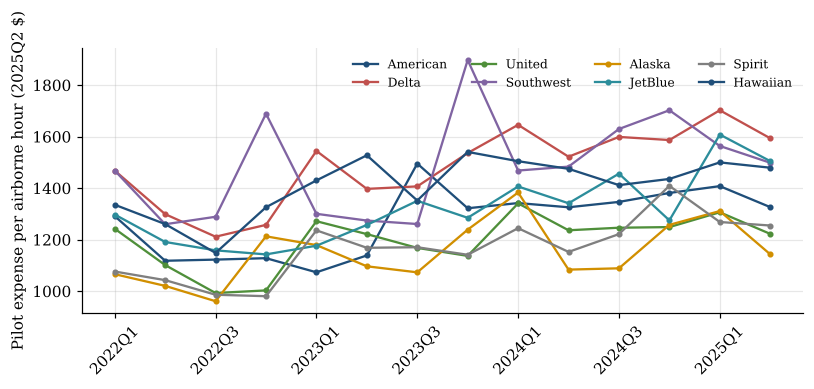

In [4]:
p52 = pd.concat([read_zip_csv(RAW / "form41" / f"P52_{y}.zip") for y in sorted({y for y, _ in QUARTERS})], ignore_index=True)
p52 = p52[(p52.REGION == "D") & p52[["YEAR", "QUARTER"]].apply(tuple, axis=1).isin(QUARTERS)]
cols = ["TOT_AIR_OP_EXPENSES", "PILOT_FLY_OPS", "FUEL_FLY_OPS", "TOTAL_AIR_HOURS", "AIR_FUELS_ISSUED"]
cq = p52.groupby(["UNIQUE_CARRIER", "YEAR", "QUARTER"], as_index=False)[cols].sum()
cq = cq[cq.TOTAL_AIR_HOURS > 0].rename(columns={"UNIQUE_CARRIER": "carrier", "YEAR": "Year", "QUARTER": "Quarter"})
cq["defl"] = [deflator.loc[(y, q)] for y, q in zip(cq.Year, cq.Quarter)]
cq["pilot_hr"] = cq.PILOT_FLY_OPS / cq.TOTAL_AIR_HOURS * cq.defl
cq["exfuel_hr"] = (cq.TOT_AIR_OP_EXPENSES - cq.FUEL_FLY_OPS) / cq.TOTAL_AIR_HOURS * cq.defl
gal = cq.groupby("carrier").apply(lambda d: d.AIR_FUELS_ISSUED.sum() / d.TOTAL_AIR_HOURS.sum()).rename("gal_hr")
cq = cq.merge(gal, on="carrier")
cq.to_parquet(CLEAN / "form41_carrier_quarter.parquet", index=False)
piv = cq[cq.carrier.isin(MAJOR_CARRIERS)].pivot_table(index="carrier", columns=["Year", "Quarter"], values="pilot_hr")
fig, ax = plt.subplots(figsize=(7.5, 3.3))
for i, c in enumerate(["AA", "DL", "UA", "WN", "AS", "B6", "NK", "HA"]):
    if c in piv.index:
        ax.plot(range(piv.shape[1]), piv.loc[c].values, marker="o", ms=3, label=CARRIER_NAMES[c], color=(PALETTE * 2)[i])
ax.set_xticks(range(piv.shape[1])[::2]); ax.set_xticklabels([qlabel(*k) for k in piv.columns][::2], rotation=45)
ax.set_ylabel("Pilot expense per airborne hour (2025Q2 $)"); ax.legend(ncol=4, fontsize=8)
fig.tight_layout(); savefig(fig, "pilot_cost_per_hour")

## Airborne time and seats from T-100

In [5]:
t100 = pd.concat([read_zip_csv(RAW / "t100" / f"T100_domestic_segment_{y}.zip") for y in sorted({y for y, _ in QUARTERS})])
t100 = t100[(t100.CLASS == "F") & (t100.AIRCRAFT_CONFIG == 1) & (t100.DEPARTURES_PERFORMED > 0) & (t100.AIR_TIME > 0)]
w = t100.DEPARTURES_PERFORMED
X = np.c_[np.ones(len(t100)), t100.DISTANCE]
yv = t100.AIR_TIME / t100.DEPARTURES_PERFORMED / 60
coef = np.linalg.lstsq(X * np.sqrt(w.values)[:, None], yv * np.sqrt(w.values), rcond=None)[0]
print(f"airborne hours per departure = {coef[0]:.3f} + {coef[1]*1000:.3f} x (thousand miles)")
seats = t100.groupby("UNIQUE_CARRIER").apply(lambda d: d.SEATS.sum() / d.DEPARTURES_PERFORMED.sum()).rename("seats_dep")

airborne hours per departure = 0.320 + 1.927 x (thousand miles)


## Product-level cost shifters

In [6]:
fallback = cq.groupby(["Year", "Quarter"])[["pilot_hr", "exfuel_hr", "gal_hr"]].median()
def cost_shifters(p):
    d = p[["carrier", "Year", "Quarter", "nonstop", "miles_flown"]].copy()
    d["air_hours"] = (2 - d.nonstop) * coef[0] + coef[1] * d.miles_flown
    d = d.merge(cq[["carrier", "Year", "Quarter", "pilot_hr", "exfuel_hr", "gal_hr"]], on=["carrier", "Year", "Quarter"], how="left")
    fb = fallback.reindex(list(zip(d.Year, d.Quarter))).reset_index(drop=True)
    for c in ["pilot_hr", "exfuel_hr", "gal_hr"]:
        d[c] = d[c].fillna(fb[c])
    d["seats"] = d.carrier.map(seats).fillna(seats.median()).clip(lower=50)
    d["fuel"] = pd.Series(list(zip(d.Year, d.Quarter))).map(fuel_q).values
    out = pd.DataFrame(index=p.index)
    out["air_hours"] = d.air_hours.values
    out["cs_fuel"] = (d.fuel * d.gal_hr * d.air_hours / d.seats / 100).values      # $100 per seat
    out["cs_pilot"] = (d.pilot_hr * d.air_hours / d.seats / 100).values
    out["cs_exfuel"] = (d.exfuel_hr * d.air_hours / d.seats / 100).values
    return out

for definition in ["airport_nondir", "airport_dir", "city_nondir"]:
    p = pd.read_parquet(CLEAN / f"products_{definition}.parquet")
    cs = cost_shifters(p)
    p = pd.concat([p.drop(columns=[c for c in cs.columns if c in p.columns]), cs], axis=1)
    p.to_parquet(CLEAN / f"products_{definition}.parquet", index=False)
    print(definition, cs.describe().loc[["mean", "std", "min", "max"]].round(3).to_dict())

airport_nondir {'air_hours': {'mean': 3.406, 'std': 1.625, 'min': 0.455, 'max': 12.039}, 'cs_fuel': {'mean': 0.554, 'std': 0.312, 'min': 0.051, 'max': 4.38}, 'cs_pilot': {'mean': 0.27, 'std': 0.137, 'min': 0.028, 'max': 1.21}, 'cs_exfuel': {'mean': 0.83, 'std': 0.419, 'min': 0.09, 'max': 4.518}}


airport_dir {'air_hours': {'mean': 3.324, 'std': 1.609, 'min': 0.455, 'max': 12.136}, 'cs_fuel': {'mean': 0.54, 'std': 0.31, 'min': 0.051, 'max': 4.028}, 'cs_pilot': {'mean': 0.264, 'std': 0.137, 'min': 0.03, 'max': 1.204}, 'cs_exfuel': {'mean': 0.807, 'std': 0.418, 'min': 0.093, 'max': 4.554}}


city_nondir {'air_hours': {'mean': 3.366, 'std': 1.645, 'min': 0.455, 'max': 12.039}, 'cs_fuel': {'mean': 0.547, 'std': 0.314, 'min': 0.051, 'max': 4.38}, 'cs_pilot': {'mean': 0.266, 'std': 0.138, 'min': 0.028, 'max': 1.21}, 'cs_exfuel': {'mean': 0.82, 'std': 0.423, 'min': 0.09, 'max': 4.518}}


In [7]:
p = pd.read_parquet(CLEAN / "products_airport_nondir.parquet")
cs_desc = (p[["cs_fuel", "cs_pilot", "cs_exfuel", "air_hours"]] * [100, 100, 100, 1]).describe(percentiles=[0.1, 0.5, 0.9]).T[["mean", "std", "10%", "50%", "90%"]]
cs_desc.index = ["Fuel cost per seat ($)", "Pilot cost per seat ($)", "Non-fuel operating cost per seat ($)", "Airborne hours"]
save_table(cs_desc, "cost_shifters", float_format="%.2f",
           note="Product-level engineering cost shifters built from Form 41 P-5.2, T-100 and the Gulf Coast jet fuel price; 2025Q2 dollars.")
cs_desc

saved /home/user/BLP-/output/tables/cost_shifters.tex


,mean,std,10%,50%,90%
Fuel cost per seat ($),55.397965,31.221644,24.498411,48.446695,94.765564
Pilot cost per seat ($),27.003188,13.697507,12.530829,24.186249,44.731109
Non-fuel operating cost per seat ($),83.016204,41.901032,39.388133,74.354472,135.959289
Airborne hours,3.405506,1.625212,1.699353,3.057961,5.430169


## Household income distribution by CBSA (ACS 2020–2024)

In [8]:
acs = pd.read_csv(RAW / "census" / "acsdt5y2024-b19001.dat", sep="|", dtype={"GEO_ID": str})
acs = acs[acs.GEO_ID.str.startswith("310M")].copy()
acs["CBSA"] = acs.GEO_ID.str[-5:]
bins = [0, 10, 15, 20, 25, 30, 35, 40, 45, 50, 60, 75, 100, 125, 150, 200, 400]   # $000; top bracket capped at $400k
ecols = [f"B19001_E{k:03d}" for k in range(2, 18)]
inc = acs[["CBSA"] + ecols].set_index("CBSA").astype(float)
inc = inc.div(inc.sum(axis=1), axis=0)
inc.columns = [f"{bins[i]}-{bins[i+1]}" for i in range(16)]
inc.to_parquet(CLEAN / "acs_income_brackets.parquet")
print(len(inc), "CBSAs with income distributions")
mid = np.array([(bins[i] + bins[i + 1]) / 2 for i in range(16)])
(inc @ mid).describe()

935 CBSAs with income distributions


count    935.000000
mean      88.824160
std       17.732914
min       25.963324
25%       77.660901
50%       86.411891
75%       97.129438
max      179.260888
dtype: float64